# **Devixo Solutions – AI/ML Internship Program**
## **Task 01: Python Programming, Data Analysis & Visual**
## **Project: Hotel Booking Dataset**


# PART 1 – DATA LOADING & DATA UNDERSTANDING

# 1.1 Import Required Libraries


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
os.makedirs("images", exist_ok=True)
os.makedirs("dataset", exist_ok=True)
print("Libraries imported successfully")

Libraries imported successfully


## 1.2 Load the Dataset
The raw file uses the text NULL for missing values, so na_values=['NULL'] is passed so Pandas treats them as real missing values.

In [2]:
URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"

try:
    df = pd.read_csv(URL, na_values=["NULL"])
except Exception as e:
    print("Download failed:", e, "\nPlease upload hotel_bookings.csv from Kaggle")
    from google.colab import files
    up = files.upload()
    df = pd.read_csv(list(up.keys())[0], na_values=["NULL"])

df.to_csv("dataset/hotel_bookings.csv", index=False)
print("Dataset loaded:", df.shape)

Dataset loaded: (119390, 32)


## 1.3 Display Dataset Records

In [3]:
print("First 5 records"); display(df.head())
print("Last 5 records"); display(df.tail())
print("Random sample of 5 records"); display(df.sample(5, random_state=42))

First 5 records


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Last 5 records


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,0.0,0,BB,BEL,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,0.0,0,BB,FRA,Online TA,TA/TO,0,0,0,E,E,0,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,0.0,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,0.0,0,HB,DEU,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


Random sample of 5 records


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
30946,Resort Hotel,0,203,2016,December,49,2,2,5,2,0.0,0,BB,GBR,Direct,Direct,0,0,0,F,F,4,No Deposit,250.0,NaN,0,Transient,66.8,0,0,Check-Out,2016-12-09
40207,City Hotel,1,82,2015,July,29,16,0,3,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,76.5,0,0,Canceled,2015-07-16
103708,City Hotel,0,25,2016,December,53,27,0,3,3,0.0,0,BB,BRA,Offline TA/TO,TA/TO,0,0,0,A,K,2,No Deposit,220.0,NaN,0,Transient-Party,60.0,0,1,Check-Out,2016-12-30
85144,City Hotel,0,1,2016,March,11,9,0,1,1,0.0,0,BB,SWE,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient-Party,95.0,0,0,Check-Out,2016-03-10
109991,City Hotel,0,70,2017,April,16,16,2,2,2,0.0,0,SC,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,108.0,0,0,Check-Out,2017-04-20


## 1.4 Dataset Information

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [5]:
print("Column names:\n", list(df.columns))
print("\nMissing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Column names:
 ['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']

Missing values per column:
children         4
country        488
agent        16340
company     112593
dtype: int64


## 1.5 Dataset Shape

In [6]:
print("Number of Rows   :", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows   : 119390
Number of Columns: 32


## 1.6 Identify Column Types
Knowing the type of each column decides which statistics and charts are valid: numerical columns support mean, correlation and histograms; categorical columns support counts, bar charts and group comparisons; date columns support trend analysis.

In [7]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()
date_cols = ["arrival_date_year", "arrival_date_month", "arrival_date_week_number",
             "arrival_date_day_of_month", "reservation_status_date"]

print(f"Numerical columns ({len(numerical_cols)}):\n{numerical_cols}\n")
print(f"Categorical columns ({len(categorical_cols)}):\n{categorical_cols}\n")
print(f"Date/Time related columns:\n{date_cols}")

Numerical columns (20):
['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Categorical columns (12):
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']

Date/Time related columns:
['arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'reservation_status_date']


### Feature Description
| Column | Meaning |
|---|---|
| hotel | City Hotel or Resort Hotel |
| is_canceled | 1 = booking cancelled, 0 = not cancelled |
| lead_time | Days between booking and arrival |
| arrival_date_* | Year, month, week and day of arrival |
| stays_in_weekend_nights / stays_in_week_nights | Nights stayed on weekends / weekdays |
| adults, children, babies | Number of guests |
| meal | Meal plan booked (BB, HB, FB, SC) |
| country | Guest country (ISO code) |
| market_segment / distribution_channel | How the booking was made |
| is_repeated_guest | 1 if returning guest |
| previous_cancellations / previous_bookings_not_canceled | Guest history |
| reserved_room_type / assigned_room_type | Room booked vs. room given |
| booking_changes | Number of changes to the booking |
| deposit_type | No Deposit, Non Refund, Refundable |
| agent / company | ID of travel agent / company |
| days_in_waiting_list | Days before booking was confirmed |
| customer_type | Contract, Group, Transient, Transient-Party |
| adr | Average Daily Rate (price per night) |
| required_car_parking_spaces | Parking spaces requested |
| total_of_special_requests | Number of special requests |
| reservation_status / reservation_status_date | Final status and its date |

# PART 2 – DATA CLEANING & PREPROCESSING
## 2.1 Check Missing Values

In [8]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().sum() / len(df) * 100).round(2)
})
missing = missing[missing["Missing Count"] > 0].sort_values("Missing %", ascending=False)
display(missing)

,Missing Count,Missing %
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


## 2.2 Handle Missing Values
| Column | Missing | Method | Reason |
|---|---|---|---|
| company | ~94% | **Drop column** | Almost empty, so any filling would be invented data |
| agent | ~14% | Fill with **0** | Missing means the booking was made without an agent |
| country | ~0.4% | Fill with **"Unknown"** | Keeps the rows without guessing a country |
| children | 4 rows | Fill with **0** (mode) | Tiny number; 0 children is by far the most common value |

In [9]:
df_clean = df.copy()
df_clean = df_clean.drop(columns=["company"])
df_clean["agent"] = df_clean["agent"].fillna(0)
df_clean["country"] = df_clean["country"].fillna("Unknown")
df_clean["children"] = df_clean["children"].fillna(df_clean["children"].mode()[0])
print("Missing values remaining:", df_clean.isnull().sum().sum())

Missing values remaining: 0


## 2.3 Check Duplicate Records

In [10]:
dups = df_clean.duplicated().sum()
print(f"Duplicate records found: {dups} ({dups/len(df_clean)*100:.1f}%)")
rows_before = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {rows_before} | Rows after: {len(df_clean)}")
print("Duplicates remaining:", df_clean.duplicated().sum())

Duplicate records found: 32001 (26.8%)
Rows before: 119390 | Rows after: 87389
Duplicates remaining: 0


Exact duplicate rows (same value in all 31 columns) are repeated records that would inflate counts and bias averages, so they were removed.

## 2.4 Check and Correct Data Types

In [11]:
print(df_clean.dtypes)

hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent                             

Issues found:
- "arrival_date_month" is text → converted to an **ordered category** (January → December) so charts sort correctly
- "reservation_status_date" is a string → converted to **datetime**
- "children" and "agent" are floats but are whole numbers → converted to **int**
- "is_canceled" and "is_repeated_guest" are 0/1 codes → kept numeric for calculations; readable labels are added only where needed for charts
- A proper "arrival_date" datetime column is created from year + month + day

In [12]:
months = ["January","February","March","April","May","June","July",
          "August","September","October","November","December"]
df_clean["arrival_date_month"] = pd.Categorical(df_clean["arrival_date_month"], categories=months, ordered=True)
df_clean["reservation_status_date"] = pd.to_datetime(df_clean["reservation_status_date"])
df_clean["children"] = df_clean["children"].astype(int)
df_clean["agent"] = df_clean["agent"].astype(int)

month_num = df_clean["arrival_date_month"].map({m: i+1 for i, m in enumerate(months)}).astype(int)
df_clean["arrival_date"] = pd.to_datetime(dict(year=df_clean["arrival_date_year"],
                                               month=month_num,
                                               day=df_clean["arrival_date_day_of_month"]))
print(df_clean[["arrival_date_month", "reservation_status_date", "children", "agent", "arrival_date"]].dtypes)

arrival_date_month               category
reservation_status_date    datetime64[ns]
children                            int64
agent                               int64
arrival_date               datetime64[ns]
dtype: object


## 2.5 Rename Columns
Some names are long or unclear; they were shortened to be clear, consistent and easy to type.

In [13]:
df_clean = df_clean.rename(columns={
    "is_canceled": "is_cancelled",
    "adr": "average_daily_rate",
    "arrival_date_year": "arrival_year",
    "arrival_date_month": "arrival_month",
    "arrival_date_week_number": "arrival_week",
    "arrival_date_day_of_month": "arrival_day",
    "stays_in_weekend_nights": "weekend_nights",
    "stays_in_week_nights": "week_nights",
    "total_of_special_requests": "special_requests",
    "required_car_parking_spaces": "parking_spaces",
})
print(list(df_clean.columns))

['hotel', 'is_cancelled', 'lead_time', 'arrival_year', 'arrival_month', 'arrival_week', 'arrival_day', 'weekend_nights', 'week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'days_in_waiting_list', 'customer_type', 'average_daily_rate', 'parking_spaces', 'special_requests', 'reservation_status', 'reservation_status_date', 'arrival_date']


## 2.6 Check Invalid Values
Checks for values that make no logical sense in a hotel booking.

In [14]:
total_guests = df_clean["adults"] + df_clean["children"] + df_clean["babies"]
total_nights = df_clean["weekend_nights"] + df_clean["week_nights"]

print("Negative average_daily_rate     :", (df_clean["average_daily_rate"] < 0).sum())
print("Extreme average_daily_rate >1000:", (df_clean["average_daily_rate"] > 1000).sum(),
      "(max =", df_clean["average_daily_rate"].max(), ")")
print("Bookings with zero guests       :", (total_guests == 0).sum())
print("Zero-night stays                :", (total_nights == 0).sum())
print("Zero-price (adr = 0) bookings   :", (df_clean["average_daily_rate"] == 0).sum())
print("Negative lead_time              :", (df_clean["lead_time"] < 0).sum())

Negative average_daily_rate     : 1
Extreme average_daily_rate >1000: 1 (max = 5400.0 )
Bookings with zero guests       : 166
Zero-night stays                : 651
Zero-price (adr = 0) bookings   : 1778
Negative lead_time              : 0


**How they were handled**
- Negative price → impossible → **removed**
- Price above 1000 → one extreme record (5400) that is an obvious data-entry/outlier → **removed**
- Zero guests → a booking with nobody staying is not valid → **removed**
- Zero-price bookings → can be real (complimentary or internal stays), so they are **kept**, but flagged with `is_free_stay` and excluded from price analysis
- Zero-night stays → kept (cancellations / no-shows can have 0 nights recorded)

In [15]:
before = len(df_clean)
df_clean = df_clean[(df_clean["average_daily_rate"] >= 0) &
                    (df_clean["average_daily_rate"] <= 1000) &
                    ((df_clean["adults"] + df_clean["children"] + df_clean["babies"]) > 0)].reset_index(drop=True)
df_clean["is_free_stay"] = (df_clean["average_daily_rate"] == 0).astype(int)
df_clean["total_nights"] = df_clean["weekend_nights"] + df_clean["week_nights"]
df_clean["total_guests"] = df_clean["adults"] + df_clean["children"] + df_clean["babies"]
print(f"Removed {before - len(df_clean)} invalid rows | Remaining: {len(df_clean)}")

Removed 168 invalid rows | Remaining: 87221


## 2.7 Verify the Cleaned Dataset

In [16]:
print("Missing values  :", df_clean.isnull().sum().sum())
print("Duplicates      :", df_clean.duplicated().sum())
print("Shape           :", df_clean.shape)
print("\nData types:"); print(df_clean.dtypes.value_counts())
print("\nBasic statistics:"); display(df_clean.describe().T.round(2))

Missing values  : 0
Duplicates      : 0
Shape           : (87221, 35)

Data types:
int64             21
object            10
datetime64[ns]     2
category           1
float64            1
Name: count, dtype: int64

Basic statistics:


,count,mean,min,25%,50%,75%,max,std
is_cancelled,87221.0,0.275255,0.0,0.0,0.0,1.0,1.0,0.446645
lead_time,87221.0,79.976061,0.0,11.0,49.0,125.0,737.0,86.059599
arrival_year,87221.0,2016.210362,2015.0,2016.0,2016.0,2017.0,2017.0,0.686058
arrival_week,87221.0,26.834868,1.0,16.0,27.0,37.0,53.0,13.668952
arrival_day,87221.0,15.816008,1.0,8.0,16.0,23.0,31.0,8.835614
weekend_nights,87221.0,1.004643,0.0,0.0,1.0,2.0,19.0,1.027378
week_nights,87221.0,2.624058,0.0,1.0,2.0,4.0,50.0,2.03982
adults,87221.0,1.87941,0.0,2.0,2.0,2.0,55.0,0.62172
children,87221.0,0.138912,0.0,0.0,0.0,0.0,10.0,0.456286
babies,87221.0,0.010846,0.0,0.0,0.0,0.0,10.0,0.113709


In [17]:
df_clean.to_csv("dataset/hotel_bookings_cleaned.csv", index=False)
print("Cleaned dataset saved")

Cleaned dataset saved


# PART 3 – EXPLORATORY DATA ANALYSIS (EDA)
## 3.1 Descriptive Statistics
Statistics for the most important numerical variables: mean, median, mode, min, max, range, standard deviation and variance.

In [18]:
key_cols = ["lead_time", "average_daily_rate", "total_nights", "total_guests",
            "special_requests", "booking_changes", "days_in_waiting_list"]

stats = pd.DataFrame({
    "Mean": df_clean[key_cols].mean(),
    "Median": df_clean[key_cols].median(),
    "Mode": df_clean[key_cols].mode().iloc[0],
    "Min": df_clean[key_cols].min(),
    "Max": df_clean[key_cols].max(),
    "Range": df_clean[key_cols].max() - df_clean[key_cols].min(),
    "Std Dev": df_clean[key_cols].std(),
    "Variance": df_clean[key_cols].var(),
}).round(2)
display(stats)

,Mean,Median,Mode,Min,Max,Range,Std Dev,Variance
lead_time,79.98,49.0,0.0,0.0,737.0,737.0,86.06,7406.25
average_daily_rate,106.46,98.2,0.0,0.0,510.0,510.0,51.88,2691.60
total_nights,3.63,3.0,3.0,0.0,69.0,69.0,2.74,7.52
total_guests,2.03,2.0,2.0,1.0,55.0,54.0,0.79,0.62
special_requests,0.70,0.0,0.0,0.0,5.0,5.0,0.83,0.69
booking_changes,0.27,0.0,0.0,0.0,18.0,18.0,0.71,0.51
days_in_waiting_list,0.75,0.0,0.0,0.0,391.0,391.0,10.00,100.03


## 3.2 Mean
Formula: **Mean = Σx / n** (sum of all values divided by number of observations).

In [19]:
for col in ["lead_time", "average_daily_rate", "total_nights"]:
    manual = df_clean[col].sum() / len(df_clean)
    print(f"Mean {col:20s}: {manual:.2f}  (Pandas: {df_clean[col].mean():.2f})")

Mean lead_time           : 79.98  (Pandas: 79.98)
Mean average_daily_rate  : 106.46  (Pandas: 106.46)
Mean total_nights        : 3.63  (Pandas: 3.63)


The average guest books about **80 days** ahead and pays roughly **105 per night** for **3.6 nights**. Means describe the typical booking, but lead time is pulled upward by a small number of very early bookings (see median below).

## 3.3 Median

In [20]:
for col in ["lead_time", "average_daily_rate", "total_nights"]:
    print(f"Mean = {df_clean[col].mean():7.2f} | Median = {df_clean[col].median():7.2f} | {col}")

Mean =   79.98 | Median =   49.00 | lead_time
Mean =  106.46 | Median =   98.20 | average_daily_rate
Mean =    3.63 | Median =    3.00 | total_nights


The median lead time (**49 days**) is far below the mean (**80 days**). A few bookings made over a year ahead stretch the mean, so the **median is the better measure of a typical booking** when data is right-skewed with outliers.

## 3.4 Mode

In [21]:
for col in ["hotel", "meal", "market_segment", "deposit_type", "customer_type", "country", "reserved_room_type", "arrival_month"]:
    print(f"Most common {col:20s}: {df_clean[col].mode()[0]}  ({df_clean[col].value_counts().iloc[0]} bookings)")

Most common hotel               : City Hotel  (53271 bookings)
Most common meal                : BB  (67898 bookings)
Most common market_segment      : Online TA  (51550 bookings)
Most common deposit_type        : No Deposit  (86077 bookings)
Most common customer_type       : Transient  (71857 bookings)
Most common country             : PRT  (27350 bookings)
Most common reserved_room_type  : A  (56428 bookings)
Most common arrival_month       : August  (11242 bookings)


Mode is the right measure for categories. The most common guest is a **Transient** customer from **Portugal (PRT)** booking through **Online travel agents** with **BB (bed & breakfast)**.

## 3.5 Standard Deviation

In [22]:
for col in ["lead_time", "average_daily_rate", "total_nights"]:
    cv = df_clean[col].std() / df_clean[col].mean() * 100
    print(f"{col:20s} Std = {df_clean[col].std():7.2f} | Coefficient of variation = {cv:6.1f}%")

lead_time            Std =   86.06 | Coefficient of variation =  107.6%
average_daily_rate   Std =   51.88 | Coefficient of variation =   48.7%
total_nights         Std =    2.74 | Coefficient of variation =   75.6%


Lead time has the highest relative variation (the standard deviation is larger than the mean), meaning booking behaviour is very spread out, from last-minute bookings to bookings made more than a year in advance. Price varies much less around its mean.

## 3.6 Correlation Analysis

In [23]:
corr_cols = ["is_cancelled", "lead_time", "average_daily_rate", "total_nights", "total_guests",
             "special_requests", "parking_spaces", "booking_changes", "previous_cancellations",
             "is_repeated_guest", "days_in_waiting_list"]
corr = df_clean[corr_cols].corr().round(2)
display(corr)

print("\nCorrelation with cancellation (strongest first):")
print(corr["is_cancelled"].drop("is_cancelled").sort_values(key=abs, ascending=False))

,is_cancelled,lead_time,average_daily_rate,total_nights,total_guests,special_requests,parking_spaces,booking_changes,previous_cancellations,is_repeated_guest,days_in_waiting_list
is_cancelled,1.00,0.18,0.13,0.09,0.10,-0.12,-0.18,-0.09,0.05,-0.09,0.00
lead_time,0.18,1.00,0.02,0.32,0.13,0.03,-0.09,0.08,0.01,-0.15,0.13
average_daily_rate,0.13,0.02,1.00,0.06,0.40,0.15,0.04,0.01,-0.05,-0.16,-0.03
total_nights,0.09,0.32,0.06,1.00,0.11,0.04,-0.05,0.06,-0.02,-0.12,-0.01
total_guests,0.10,0.13,0.40,0.11,1.00,0.13,0.03,0.00,-0.05,-0.16,-0.02
special_requests,-0.12,0.03,0.15,0.04,0.13,1.00,0.05,0.02,0.00,-0.00,-0.05
parking_spaces,-0.18,-0.09,0.04,-0.05,0.03,0.05,1.00,0.05,-0.00,0.07,-0.02
booking_changes,-0.09,0.08,0.01,0.06,0.00,0.02,0.05,1.00,-0.01,0.01,0.02
previous_cancellations,0.05,0.01,-0.05,-0.02,-0.05,0.00,-0.00,-0.01,1.00,0.21,0.00
is_repeated_guest,-0.09,-0.15,-0.16,-0.12,-0.16,-0.00,0.07,0.01,0.21,1.00,-0.01



Correlation with cancellation (strongest first):
lead_time                 0.18
parking_spaces           -0.18
average_daily_rate        0.13
special_requests         -0.12
total_guests              0.10
total_nights              0.09
booking_changes          -0.09
is_repeated_guest        -0.09
previous_cancellations    0.05
days_in_waiting_list      0.00
Name: is_cancelled, dtype: float64


Most important correlations (correlation ranges from -1 to +1):
- **lead_time ↔ is_cancelled (+0.18):** the earlier a guest books, the more likely they cancel
- **parking_spaces ↔ is_cancelled (-0.18):** guests who request parking almost never cancel (they are committed to travelling by car)
- **special_requests ↔ is_cancelled (-0.12):** guests who make requests are more invested in the stay
- **total_nights ↔ average_daily_rate and total_guests ↔ average_daily_rate:** more guests → higher price per night

All correlations are weak-to-moderate; no single variable explains cancellation alone.

# PART 4 – DATA VISUALIZATION
Each chart is saved to the `images/` folder for the report and GitHub.

In [24]:
def save(name):
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

paid = df_clean[df_clean["average_daily_rate"] > 0]   # excludes zero-price stays for price analysis

### Visualization 1 – Histogram: Distribution of Lead Time


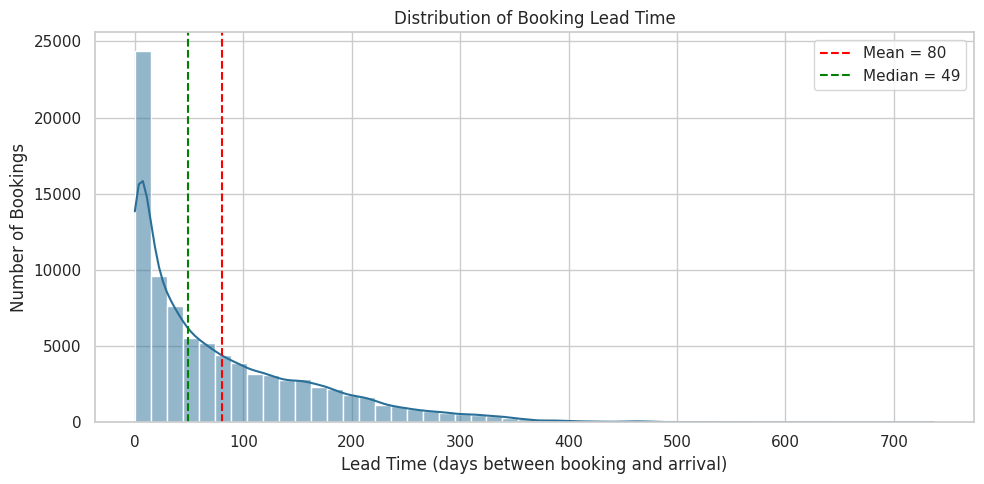

In [25]:
plt.figure(figsize=(10, 5))
sns.histplot(df_clean["lead_time"], bins=50, kde=True, color="#2a6f97")
plt.axvline(df_clean["lead_time"].mean(), color="red", linestyle="--", label=f"Mean = {df_clean['lead_time'].mean():.0f}")
plt.axvline(df_clean["lead_time"].median(), color="green", linestyle="--", label=f"Median = {df_clean['lead_time'].median():.0f}")
plt.title("Distribution of Booking Lead Time")
plt.xlabel("Lead Time (days between booking and arrival)")
plt.ylabel("Number of Bookings")
plt.legend()
save("visualization_01")

**Interpretation:** The distribution is strongly right-skewed. Most bookings are made within about 2 months of arrival, while a long tail of bookings is made 300+ days ahead. The mean (80) is pulled above the median (49) by that tail, so planning decisions should use the median.

### Visualization 2 – Bar Chart: Average Price per Night by Month

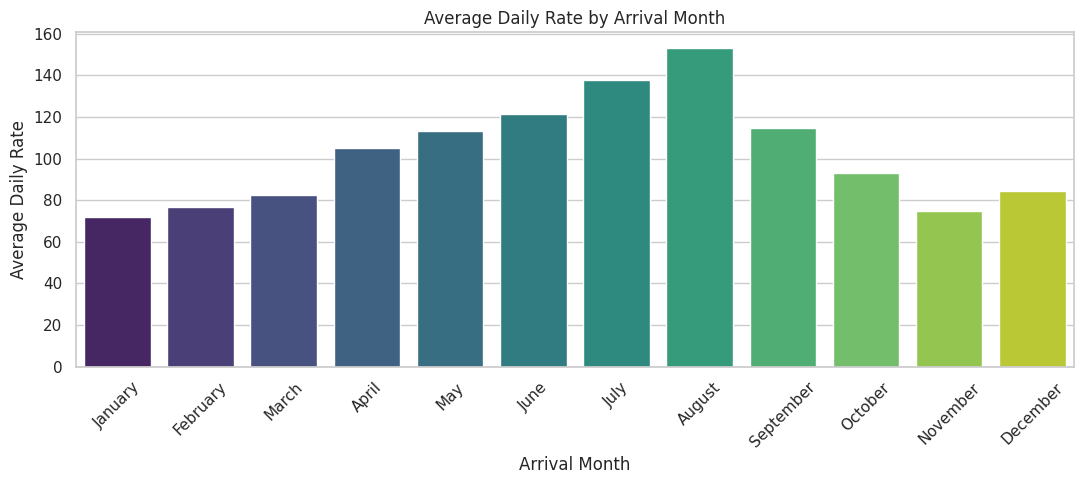

In [26]:
monthly_price = paid.groupby("arrival_month", observed=True)["average_daily_rate"].mean()
plt.figure(figsize=(11, 5))
sns.barplot(x=monthly_price.index, y=monthly_price.values, palette="viridis")
plt.title("Average Daily Rate by Arrival Month")
plt.xlabel("Arrival Month")
plt.ylabel("Average Daily Rate")
plt.xticks(rotation=45)
save("visualization_02")

**Interpretation:** Prices are clearly seasonal. August is the most expensive month and January/November the cheapest, roughly a 2x difference. Summer demand drives the highest rates, which matters for revenue planning.

### Visualization 3 – Pie Chart: Booking Cancellation Share

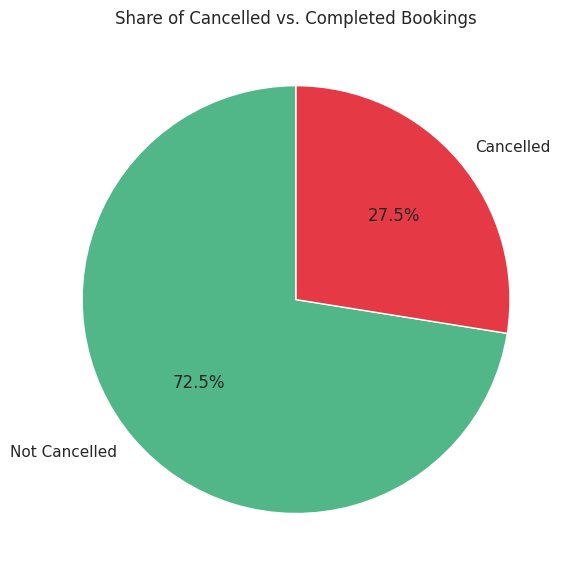

In [27]:
counts = df_clean["is_cancelled"].map({0: "Not Cancelled", 1: "Cancelled"}).value_counts()
plt.figure(figsize=(6, 6))
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
        colors=["#52b788", "#e63946"], wedgeprops={"edgecolor": "white"})
plt.title("Share of Cancelled vs. Completed Bookings")
save("visualization_03")

**Interpretation:** Roughly **1 in 4 bookings (27.5%) is cancelled**. For a hotel this is a significant revenue risk and the reason overbooking and deposit policies matter.

### Visualization 4 – Scatter Plot: Lead Time vs. Average Daily Rate

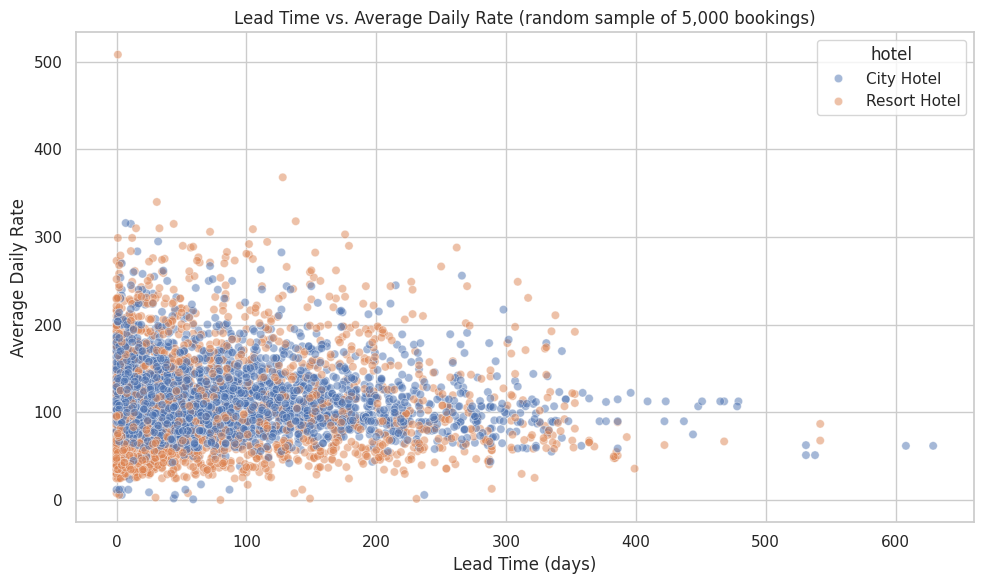

In [28]:
sample = paid.sample(5000, random_state=42)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample, x="lead_time", y="average_daily_rate", hue="hotel", alpha=0.5)
plt.title("Lead Time vs. Average Daily Rate (random sample of 5,000 bookings)")
plt.xlabel("Lead Time (days)")
plt.ylabel("Average Daily Rate")
save("visualization_04")

**Interpretation:** There is no strong linear relationship between how early someone books and the price they pay. Price depends more on season and room type than on booking time. Resort Hotel prices show a wider vertical spread (standard deviation about 63 vs. 40 for the City Hotel), consistent with stronger price seasonality.

### Visualization 5 – Line Chart: Monthly Bookings Over Time

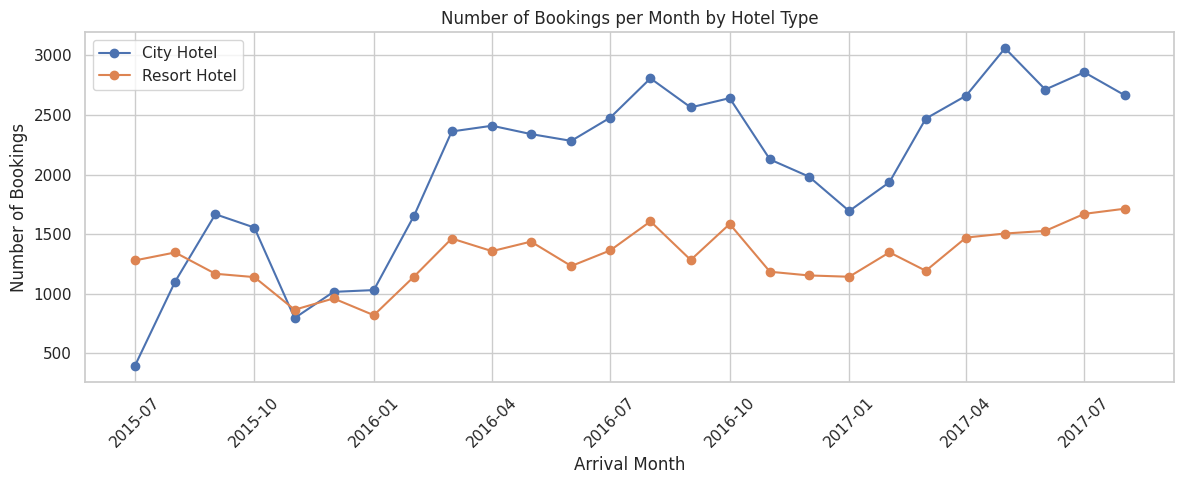

In [29]:
monthly = df_clean.groupby([df_clean["arrival_date"].dt.to_period("M"), "hotel"]).size().unstack()
monthly.index = monthly.index.to_timestamp()
plt.figure(figsize=(12, 5))
for h in monthly.columns:
    plt.plot(monthly.index, monthly[h], marker="o", label=h)
plt.title("Number of Bookings per Month by Hotel Type")
plt.xlabel("Arrival Month")
plt.ylabel("Number of Bookings")
plt.legend()
plt.xticks(rotation=45)
save("visualization_05")

**Interpretation:** Both hotels show a repeating yearly pattern with peaks in spring/summer and dips in winter. The City Hotel has more bookings overall and swings more from month to month, while the Resort Hotel's monthly volume is steadier (its seasonality shows up in price instead, see Visualization 4).

### Visualization 6 – Box Plot: Price by Customer Type

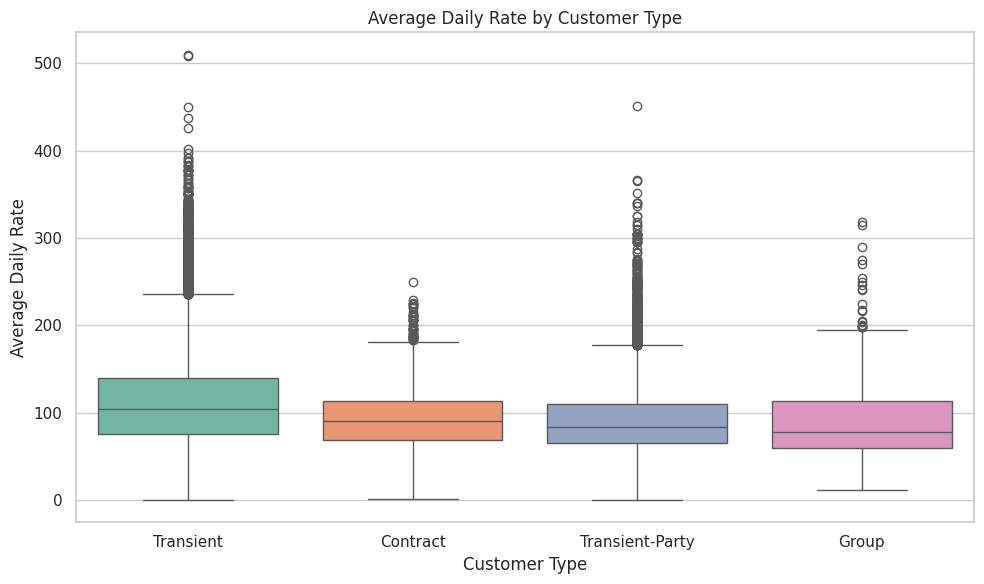

In [30]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=paid, x="customer_type", y="average_daily_rate", palette="Set2")
plt.title("Average Daily Rate by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Average Daily Rate")
save("visualization_06")

**Interpretation:** Transient guests pay the highest typical rate (median about 104) and have the most high-price outliers. Contract, Group and Transient-Party customers pay noticeably less (medians about 78 to 91), which fits negotiated or bundled pricing.

### Visualization 7 – Correlation Heatmap

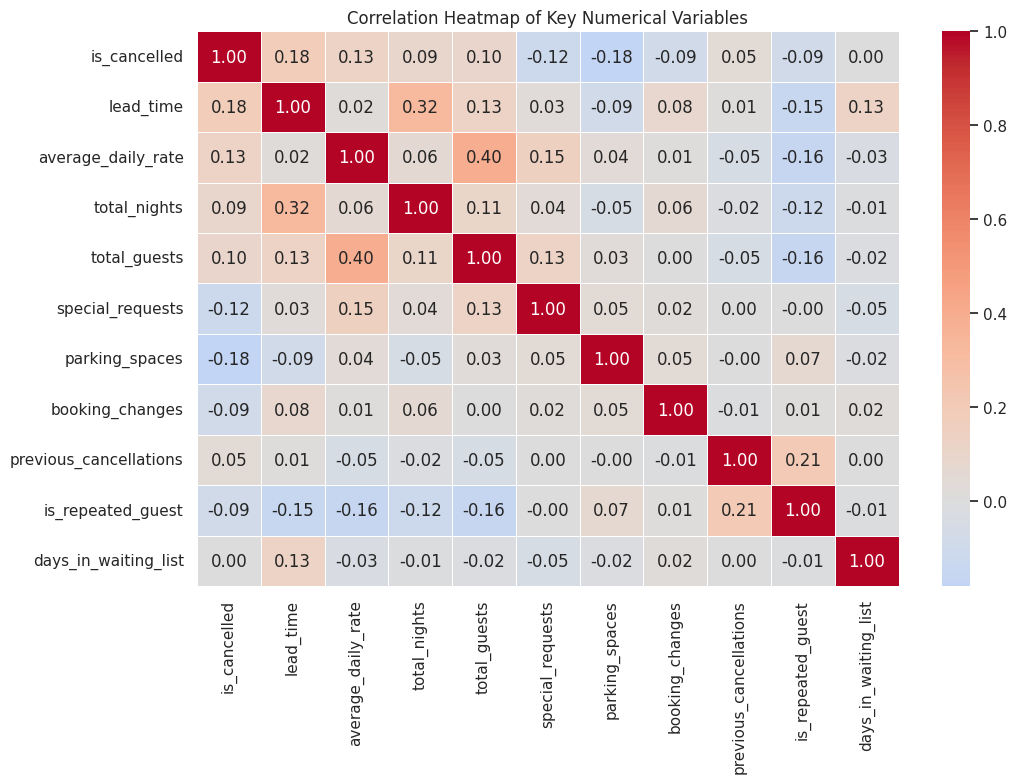

In [31]:
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Key Numerical Variables")
save("visualization_07")

**Interpretation:** Correlations are mostly weak. The strongest links with cancellation are lead time (positive) and parking spaces / special requests (negative). `is_repeated_guest` and `previous_cancellations` show only small relationships.

### Visualization 8 – Count Plot: Bookings by Deposit Type and Cancellation

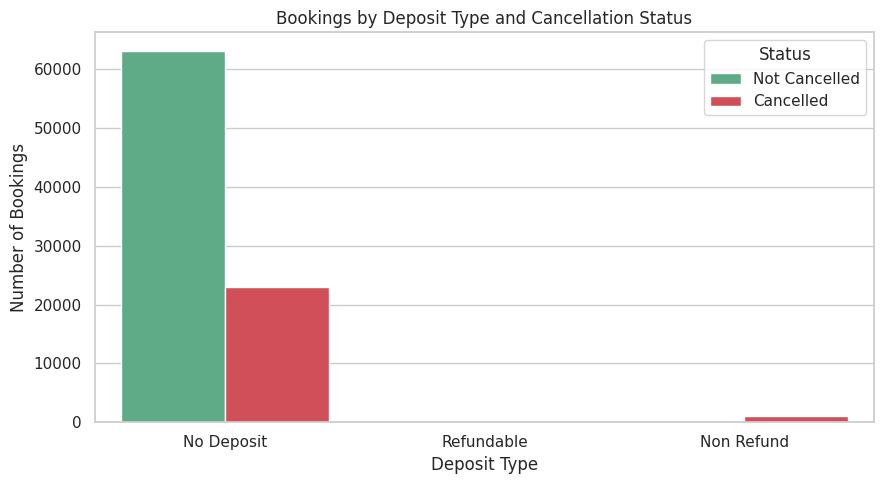

In [32]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df_clean, x="deposit_type", hue=df_clean["is_cancelled"].map({0: "Not Cancelled", 1: "Cancelled"}),
              palette=["#52b788", "#e63946"])
plt.title("Bookings by Deposit Type and Cancellation Status")
plt.xlabel("Deposit Type")
plt.ylabel("Number of Bookings")
plt.legend(title="Status")
save("visualization_08")

**Interpretation:** Most bookings are 'No Deposit'. The surprising finding is that **Non-Refundable bookings are cancelled about 95% of the time**, the opposite of what you would expect. These are mostly group/agent bookings that are blocked early and cancelled later.

### Visualization 9 – Pair Plot

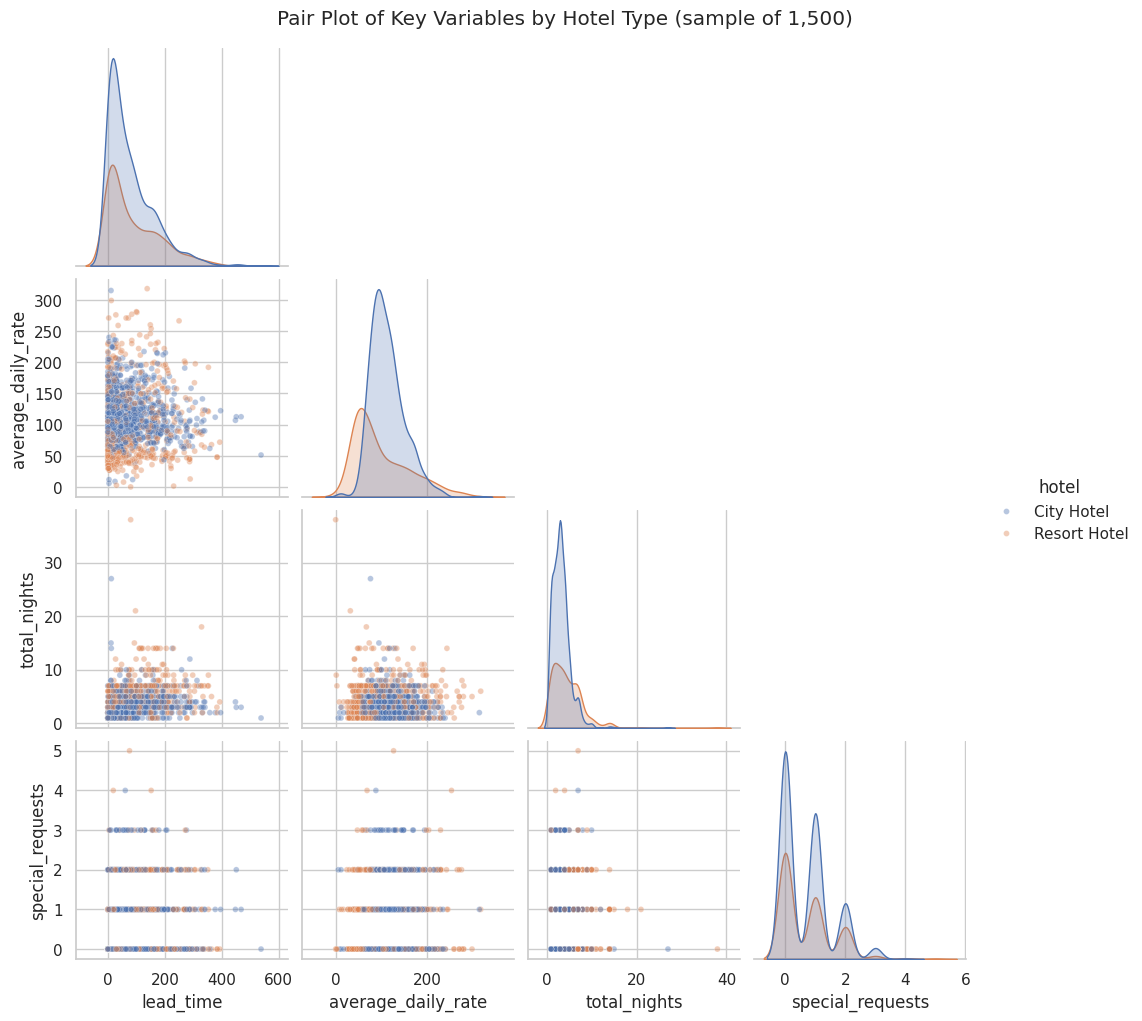

In [33]:
pair_cols = ["lead_time", "average_daily_rate", "total_nights", "special_requests", "hotel"]
pair_sample = paid[pair_cols].sample(1500, random_state=42)
g = sns.pairplot(pair_sample, hue="hotel", corner=True, plot_kws={"alpha": 0.4, "s": 18})
g.fig.suptitle("Pair Plot of Key Variables by Hotel Type (sample of 1,500)", y=1.02)
g.savefig("images/visualization_09.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** The pair plot shows each variable's distribution and pairwise relationships at once. Lead time and total nights are right-skewed; no pair shows a strong linear pattern, and City and Resort bookings overlap heavily except in price spread.

### Visualization 10 – Violin Plot: Lead Time by Cancellation Status

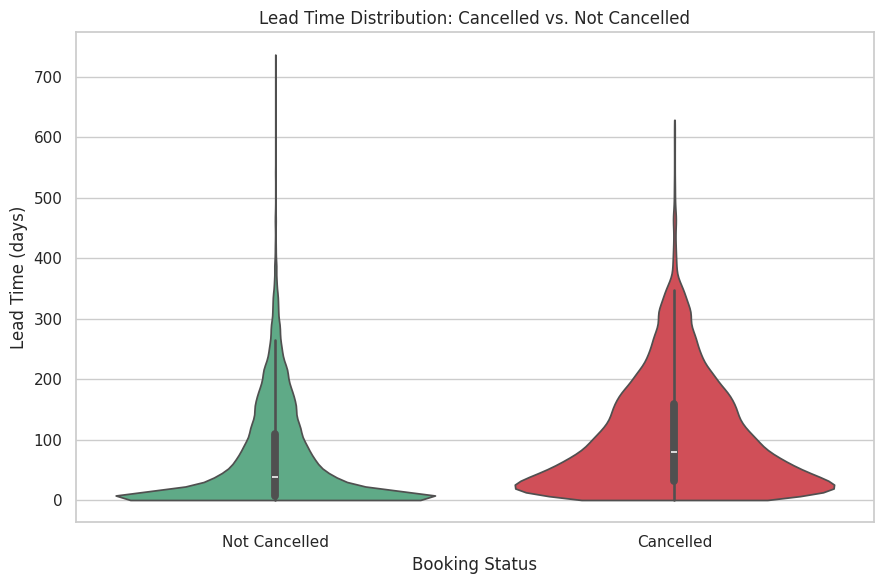

In [34]:
plt.figure(figsize=(9, 6))
sns.violinplot(data=df_clean, x=df_clean["is_cancelled"].map({0: "Not Cancelled", 1: "Cancelled"}),
               y="lead_time", palette=["#52b788", "#e63946"], cut=0)
plt.title("Lead Time Distribution: Cancelled vs. Not Cancelled")
plt.xlabel("Booking Status")
plt.ylabel("Lead Time (days)")
save("visualization_10")

**Interpretation:** Cancelled bookings have a much higher median lead time (**80 days**) than kept bookings (**38 days**). The longer the gap between booking and arrival, the more time for plans to change.

# PART 5 – DATA INSIGHTS & FINDINGS
All numbers below are calculated live from the cleaned dataset.

In [35]:
canc = df_clean["is_cancelled"].mean() * 100
hotel_c = df_clean.groupby("hotel")["is_cancelled"].mean() * 100
price_m = paid.groupby("arrival_month", observed=True)["average_daily_rate"].mean()
dep_c = df_clean.groupby("deposit_type")["is_cancelled"].mean() * 100
seg_c = df_clean.groupby("market_segment")["is_cancelled"].mean() * 100
seg_c = seg_c[df_clean["market_segment"].value_counts()[lambda s: s > 100].index]
hotel_p = paid.groupby("hotel")["average_daily_rate"].mean()
sr = df_clean.groupby("special_requests")["is_cancelled"].mean() * 100
lt = df_clean.groupby("is_cancelled")["lead_time"].median()
top_c = df_clean["country"].value_counts()
yr = df_clean.groupby("arrival_year").size()
q1, q3 = paid["average_daily_rate"].quantile([.25, .75])
outl = (paid["average_daily_rate"] > q3 + 1.5 * (q3 - q1)).sum()

insights = [
 f"1. Overall cancellation rate is {canc:.1f}% - roughly 1 in 4 bookings never turns into a stay.",
 f"2. City Hotel cancels more ({hotel_c['City Hotel']:.1f}%) than Resort Hotel ({hotel_c['Resort Hotel']:.1f}%).",
 f"3. Lead time is the strongest numeric driver of cancellation (corr = {corr.loc['lead_time','is_cancelled']:.2f}); cancelled bookings have a median lead of {lt[1]:.0f} days vs {lt[0]:.0f} days for kept ones.",
 f"4. {price_m.idxmax()} has the highest average price ({price_m.max():.0f}) and {price_m.idxmin()} the lowest ({price_m.min():.0f}) - a {price_m.max()/price_m.min():.1f}x seasonal gap.",
 f"5. City Hotel averages {hotel_p['City Hotel']:.0f} per night versus {hotel_p['Resort Hotel']:.0f} for the Resort Hotel.",
 f"6. Non-Refundable deposits are cancelled {dep_c['Non Refund']:.1f}% of the time versus {dep_c['No Deposit']:.1f}% for No Deposit - an unexpected result.",
 f"7. Online TA is the riskiest major segment ({seg_c['Online TA']:.1f}% cancelled); Corporate is the safest ({seg_c['Corporate']:.1f}%).",
 f"8. Guests with 0 special requests cancel {sr[0]:.1f}% of the time; with 4 requests only {sr[4]:.1f}% - engaged guests stay.",
 f"9. Portugal ({top_c.index[0]}) is the top origin country with {top_c.iloc[0]/len(df_clean)*100:.1f}% of bookings, followed by {top_c.index[1]} and {top_c.index[2]}.",
 f"10. Lead time has the greatest variation (std {df_clean['lead_time'].std():.0f} vs mean {df_clean['lead_time'].mean():.0f}); mean is far above median ({df_clean['lead_time'].median():.0f}) because of long-tail early bookings.",
 f"11. {outl} bookings are price outliers (above the IQR upper fence), which is a small share of all paid bookings and are kept because they are plausible premium stays.",
 f"12. Booking volume by arrival year: " + ", ".join(f"{y}: {n}" for y, n in yr.items()) + " (2015 and 2017 are partial years in the data).",
 f"13. Parking requests show the strongest negative link with cancellation ({corr.loc['parking_spaces','is_cancelled']:.2f}): guests who need parking rarely cancel.",
]
for i in insights:
    print(i, "\n")

1. Overall cancellation rate is 27.5% - roughly 1 in 4 bookings never turns into a stay. 

2. City Hotel cancels more (30.1%) than Resort Hotel (23.5%). 

3. Lead time is the strongest numeric driver of cancellation (corr = 0.18); cancelled bookings have a median lead of 80 days vs 38 days for kept ones. 

4. August has the highest average price (153) and January the lowest (72) - a 2.1x seasonal gap. 

5. City Hotel averages 113 per night versus 101 for the Resort Hotel. 

6. Non-Refundable deposits are cancelled 94.7% of the time versus 26.7% for No Deposit - an unexpected result. 

7. Online TA is the riskiest major segment (35.4% cancelled); Corporate is the safest (12.1%). 

8. Guests with 0 special requests cancel 33.3% of the time; with 4 requests only 10.6% - engaged guests stay. 

9. Portugal (PRT) is the top origin country with 31.4% of bookings, followed by GBR and FRA. 

10. Lead time has the greatest variation (std 86 vs mean 80); mean is far above median (49) because of l

# PART 6 – FINAL CONCLUSION
This project analysed the **Hotel Booking Demand** dataset (about 119,000 raw bookings from a City Hotel and a Resort Hotel in Portugal, 2015–2017) to understand booking behaviour, pricing and cancellations. During cleaning, the nearly empty `company` column was dropped, missing `agent`, `country` and `children` values were filled with logical defaults, about 32,000 duplicate rows and 168 invalid records (negative/extreme prices, zero guests) were removed, data types were corrected, and columns were renamed, leaving a clean dataset of about 87,200 bookings. Descriptive statistics (mean, median, mode, standard deviation, variance), correlation analysis, and 11 visualizations were used to explore the data.

The most important findings are that about **27.5% of bookings are cancelled**, cancellations rise with **lead time** and with **Online TA** bookings, guests with parking or special requests rarely cancel, prices are strongly **seasonal** (August is about twice as expensive as January), and **Non-Refundable** bookings are cancelled at an unexpectedly high rate. These patterns could help hotels set overbooking levels, deposit policies and seasonal pricing. This task also built the practical foundation (cleaning, EDA, visual analysis) needed for later feature engineering and cancellation-prediction models.

# BONUS – STREAMLIT DASHBOARD
Run these two cells to create `app.py` and launch the dashboard from Colab (needs a free ngrok token from https://dashboard.ngrok.com/get-started/your-authtoken).

In [36]:
%%writefile app.py
import pandas as pd
import streamlit as st
import plotly.express as px

st.set_page_config(page_title="Hotel Booking Dashboard", layout="wide")
st.title("🏨 Hotel Booking Demand Dashboard")

@st.cache_data
def load():
    return pd.read_csv("dataset/hotel_bookings_cleaned.csv", parse_dates=["arrival_date"])

df = load()

st.sidebar.header("Filters")
hotel = st.sidebar.multiselect("Hotel", df["hotel"].unique(), default=list(df["hotel"].unique()))
year = st.sidebar.multiselect("Arrival Year", sorted(df["arrival_year"].unique()), default=list(sorted(df["arrival_year"].unique())))
seg = st.sidebar.multiselect("Market Segment", df["market_segment"].unique(), default=list(df["market_segment"].unique()))
f = df[df["hotel"].isin(hotel) & df["arrival_year"].isin(year) & df["market_segment"].isin(seg)]

c1, c2, c3, c4, c5 = st.columns(5)
c1.metric("Total Records", f"{len(f):,}")
c2.metric("Total Columns", df.shape[1])
c3.metric("Cancellation Rate", f"{f['is_cancelled'].mean()*100:.1f}%")
c4.metric("Avg Daily Rate", f"{f.loc[f['average_daily_rate']>0,'average_daily_rate'].mean():.0f}")
c5.metric("Avg Lead Time", f"{f['lead_time'].mean():.0f} days")

a, b = st.columns(2)
months = ["January","February","March","April","May","June","July","August","September","October","November","December"]
price = f[f["average_daily_rate"] > 0].groupby("arrival_month")["average_daily_rate"].mean().reindex(months).reset_index()
a.plotly_chart(px.bar(price, x="arrival_month", y="average_daily_rate", title="Average Daily Rate by Month"), use_container_width=True)
canc = f.groupby("market_segment")["is_cancelled"].mean().mul(100).reset_index()
b.plotly_chart(px.bar(canc, x="market_segment", y="is_cancelled", title="Cancellation Rate (%) by Market Segment"), use_container_width=True)

st.plotly_chart(px.histogram(f, x="lead_time", nbins=50, color="hotel", title="Lead Time Distribution"), use_container_width=True)

st.subheader("Correlation")
cols = ["is_cancelled","lead_time","average_daily_rate","total_nights","special_requests","parking_spaces","booking_changes"]
st.plotly_chart(px.imshow(f[cols].corr().round(2), text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1), use_container_width=True)

st.subheader("Summary Statistics")
st.dataframe(f[["lead_time","average_daily_rate","total_nights","special_requests"]].describe().round(2))

st.subheader("Key Insights")
st.markdown("""
- About 1 in 4 bookings is cancelled; longer lead time means a higher cancellation risk.
- Prices peak in summer (August) and are lowest in winter.
- Online TA bookings cancel most; Corporate and Direct cancel least.
- Guests with parking or special requests rarely cancel.
""")

Writing app.py


In [38]:
!pip install -q streamlit pyngrok plotly
from pyngrok import ngrok
import subprocess, time

NGROK_TOKEN = "3HSNSVVvqxeJ2DkaW7TJDiBEEC9_3PAjiJhd4hvd4fKBTAyFz"
ngrok.set_auth_token(NGROK_TOKEN)
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"])
time.sleep(5)
print("Dashboard URL:", ngrok.connect(8501))

Dashboard URL: NgrokTunnel: "https://canyon-ladies-divisive.ngrok-free.dev" -> "http://localhost:8501"


# DOWNLOAD PROJECT FILES
Zips the dataset, images, notebook outputs and `app.py` for GitHub upload.

In [39]:
!zip -r Task_01_AI_ML_files.zip dataset images app.py
from google.colab import files
files.download("Task_01_AI_ML_files.zip")

  adding: dataset/ (stored 0%)
  adding: dataset/hotel_bookings.csv (deflated 92%)
  adding: dataset/hotel_bookings_cleaned.csv (deflated 90%)
  adding: images/ (stored 0%)
  adding: images/visualization_01.png (deflated 13%)
  adding: images/visualization_06.png (deflated 21%)
  adding: images/visualization_08.png (deflated 21%)
  adding: images/visualization_03.png (deflated 10%)
  adding: images/visualization_10.png (deflated 13%)
  adding: images/visualization_02.png (deflated 18%)
  adding: images/visualization_05.png (deflated 8%)
  adding: images/visualization_09.png (deflated 5%)
  adding: images/visualization_04.png (deflated 2%)
  adding: images/visualization_07.png (deflated 8%)
  adding: app.py (deflated 56%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>